# Reproducible Data Processing and Validation

This notebook independently reproduces the **variable checks, cleaning, PSID linkage, analysis filters, ELS summaries, and NLSY97–Opportunity Insights comparison** documented in Sections 4 and 5 of `DATASHEET.md`. It does not depend on `eda.ipynb` or modify any raw files.

**Inputs:** the six original files under `data/raw/` as listed below. **Dependencies:** `pandas`, `polars`, `numpy`, `matplotlib`, `xlrd`, `ipykernel` (install with `python -m pip install pandas polars numpy matplotlib xlrd ipykernel`). Run all cells from top to bottom, with the repository root as the working directory. The notebook reports observed codes and counts; official survey definitions and publisher download links must be verified separately.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

ROOT = Path.cwd()

if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT / "cs418-family-background-outcomes"

if not (ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Could not find data/raw. Run from the repository folder.")
def source(relative_path):
    path = ROOT / "data" / "raw" / relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Add the raw file to its documented folder.")
    return path

def report(name, df):
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


## 1. PSID — raw dimensions and missing-code checks

In [11]:
psid = pl.read_csv(source("psid/J365605.csv"))
linkage = pl.read_csv(source("psid/M365605.csv"))
report("PSID analysis", psid)
report("PSID linkage", linkage)

psid_missing_codes = {"ER12222": 99, "ER12223": 99, "TA210679": 9999999}
psid_clean = psid.with_columns([
    pl.when(pl.col(col) == sentinel).then(None).otherwise(pl.col(col)).alias(col)
    for col, sentinel in psid_missing_codes.items()
])
psid_summary = []
for col, sentinel in psid_missing_codes.items():
    psid_summary.append({
        "variable": col,
        "sentinel": sentinel,
        "replaced": psid.filter(pl.col(col) == sentinel).height,
        "nulls_after": psid_clean[col].null_count(),
        "min_after": psid_clean[col].min(),
        "max_after": psid_clean[col].max(),
    })
display(pd.DataFrame(psid_summary))
print("PSID rows after sentinel replacement:", psid_clean.height)

for col in ["ER12079", "TA210220", "TA210225"]:
    print(col, "nulls:", psid_clean[col].null_count(),
          "min:", psid_clean[col].min(), "max:", psid_clean[col].max())


PSID analysis: 2,362 rows × 25 columns
PSID linkage: 21,511 rows × 116 columns


,variable,sentinel,replaced,nulls_after,min_after,max_after
0,ER12222,99,102,308,0,17
1,ER12223,99,80,286,0,17
2,TA210679,9999999,121,121,0,180000


PSID rows after sentinel replacement: 2362
ER12079 nulls: 206 min: -64500.0 max: 386250.0
TA210220 nulls: 0 min: 1 max: 99
TA210225 nulls: 0 min: 0 max: 52


## 2. PSID — linkage and analysis filters

In [12]:
join_args = dict(left_on=["ER30001", "ER30002"], right_on=["CDSCUMID68", "CDSCUMPN"])
matched = psid.join(linkage, how="semi", **join_args)
unmatched = psid.join(linkage, how="anti", **join_args)
linked = psid.join(linkage, how="left", **join_args)
display(pd.DataFrame([{
    "PSID rows": psid.height, "matched": matched.height,
    "unmatched": unmatched.height, "left join rows": linked.height,
}]))

# Mirrors the original notebook's 1997 household-ID comparison.
linked = linked.with_columns(
    pl.when(
        pl.col("ER33401").is_null() | pl.col("ER33402").is_null()
        | pl.col("CRFID97").is_null() | pl.col("CRSN97").is_null()
    ).then(pl.lit("Unconfirmed"))
    .when((pl.col("ER33401") == pl.col("CRFID97")) &
          (pl.col("ER33402") == pl.col("CRSN97")))
    .then(pl.lit("Match"))
    .otherwise(pl.lit("Mismatch"))
    .alias("household_status")
)
display(linked.group_by("household_status").len().sort("household_status").to_pandas())

income_education = psid.select(["ER12079", "ER12222"]).drop_nulls().filter(pl.col("ER12222") != 99)
employment_wages = psid.filter(
    pl.col("TA210220").is_in([1, 2, 3, 5, 6, 7])
    & (pl.col("TA210679") > 0)
    & (pl.col("TA210679") != 9999999)
)
display(pd.DataFrame([
    {"analysis": "Family income vs. head education", "retained": income_education.height, "excluded": psid.height-income_education.height},
    {"analysis": "Employment status vs. wages", "retained": employment_wages.height, "excluded": psid.height-employment_wages.height},
]))


,PSID rows,matched,unmatched,left join rows
0,2362,2097,265,2362


,household_status,len
0,Match,2097
1,Unconfirmed,265


,analysis,retained,excluded
0,Family income vs. head education,2054,308
1,Employment status vs. wages,1610,752


## 3. NLSY97 — special values and cleaning

In [13]:
nlsy = pl.read_csv(source("nlsy97/NLSY97_expanded.csv"))
report("NLSY97", nlsy)
columns = ["R1204500", "R1302400", "R1302500", "U5753300", "U5753500", "Z9061911"]
missing_codes = [-1, -2, -3, -4, -5]
summary = []
for col in columns:
    special = nlsy.filter(pl.col(col).is_in(missing_codes)).height
    edu95 = nlsy.filter(pl.col(col) == 95).height if col in ["R1302400", "R1302500"] else None
    summary.append({"variable": col, "-1 to -5 count": special, "education code 95 count": edu95})
display(pd.DataFrame(summary))

zero_wage_rule = (nlsy["U5753300"] == 0) & (nlsy["U5753500"] == -4)
print("Records qualifying for special zero-wage recode:", zero_wage_rule.sum())

nlsy_clean = nlsy.with_columns([
    pl.when(pl.col(col).is_in(missing_codes)).then(None).otherwise(pl.col(col)).alias(col)
    for col in columns
]).with_columns([
    pl.when(pl.col(col) == 95).then(None).otherwise(pl.col(col)).alias(col)
    for col in ["R1302400", "R1302500"]
]).with_columns(
    pl.when(zero_wage_rule).then(0).otherwise(pl.col("U5753500")).alias("U5753500")
)
comparison = nlsy_clean.select(["R1204500", "U5753500"]).drop_nulls()
print("NLSY97 income/wages complete cases:", comparison.height)
print("Excluded from comparison:", nlsy.height - comparison.height)
print("Negative income values (not automatically removed):", nlsy_clean.filter(pl.col("R1204500") < 0).height)


NLSY97: 8,984 rows × 12 columns


,variable,-1 to -5 count,education code 95 count
0,R1204500,2396,NaN
1,R1302400,1856,8.0
2,R1302500,688,6.0
3,U5753300,2327,NaN
4,U5753500,3783,NaN
5,Z9061911,1746,NaN


Records qualifying for special zero-wage recode: 1162
NLSY97 income/wages complete cases: 4725
Excluded from comparison: 4259
Negative income values (not automatically removed): 3


## 4. Opportunity Insights — selected columns and quality checks

In [14]:
oi = pd.read_excel(source("opportunity_insights/gender_nat.xls"))
report("Opportunity Insights", oi)
selected = ["par_pctile", "w2wages_30_f", "w2wages_30_m"]
display(oi[selected].agg(["min", "max"]).T)
print("Missing values:")
display(oi[selected].isna().sum().to_frame("missing"))
print("Duplicate parental percentiles:", oi["par_pctile"].duplicated().sum())
print("Negative female wages:", (oi["w2wages_30_f"] < 0).sum())
print("Negative male wages:", (oi["w2wages_30_m"] < 0).sum())
print("Complete cases:", oi[selected].dropna().shape[0])


Opportunity Insights: 100 rows × 25 columns


,min,max
par_pctile,1.000000,100.000000
w2wages_30_f,20034.866784,54231.843767
w2wages_30_m,24414.304218,81073.710454


Missing values:


,missing
par_pctile,0
w2wages_30_f,0
w2wages_30_m,0


Duplicate parental percentiles: 0
Negative female wages: 0
Negative male wages: 0
Complete cases: 100


## 5. ELS — raw rows, cleaned categories, and missing percentages

In [15]:
def load_els(relative_path):
    path = source(relative_path)
    raw = pd.read_csv(path, header=None, encoding="utf-8-sig")
    report(path.name + " (raw)", raw)
    # Raw row 0: title; row 1: SES heading; row 2: column names;
    # rows 3–6: four categories; row 7: source citation.
    cleaned = raw.iloc[3:].copy()
    cleaned.columns = ["Employment Status", "Low SES", "Middle SES", "High SES"]
    cleaned = cleaned[~cleaned["Employment Status"].astype(str).str.strip().str.startswith("Source:")]
    for col in ["Low SES", "Middle SES", "High SES"]:
        cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")
    cleaned = cleaned.reset_index(drop=True)
    report(path.name + " (cleaned)", cleaned)
    print("Missing SES percentages:", int(cleaned[["Low SES", "Middle SES", "High SES"]].isna().sum().sum()))
    display(cleaned)
    return cleaned

els_a = load_els("els/sophomorefinances2a.csv")
els_b = load_els("els/sophomorefinances2b.csv")


sophomorefinances2a.csv (raw): 8 rows × 4 columns
sophomorefinances2a.csv (cleaned): 4 rows × 4 columns
Missing SES percentages: 0


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,9.1,5.5,5.2
1,Out-of-the-labor force,4.5,4.3,7.4
2,Working 0-34 hours/week,12.8,11.8,10.9
3,Working 35+ hours/week,73.6,78.4,76.4


sophomorefinances2b.csv (raw): 8 rows × 4 columns
sophomorefinances2b.csv (cleaned): 4 rows × 4 columns
Missing SES percentages: 0


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,8.4,4.7,4.9
1,Out-of-the-labor force,4.8,4.1,7.4
2,Working 0-34 hours/week,10.8,11.1,10.5
3,Working 35+ hours/week,76.0,80.1,77.2


## 6. Rebuild analysis-ready variables and comparisons

The cells below recreate the derived variables used in the documented comparisons. They operate only on the cleaned tables created above. Percentages in ELS are group-level percentages, **not respondent counts**.

In [16]:
# PSID: analysis-specific filtered tables and mean wages by employment status
psid_income_education = psid_clean.select(["ER12079", "ER12222"]).drop_nulls()
psid_employment_wages = psid_clean.filter(
    pl.col("TA210220").is_in([1, 2, 3, 5, 6, 7]) & (pl.col("TA210679") > 0)
)
psid_average_wages = (
    psid_employment_wages.group_by("TA210220")
    .agg(pl.col("TA210679").mean().alias("Average Wages"))
    .sort("TA210220")
)
print("PSID income/education rows:", psid_income_education.height)
print("PSID employment/wages rows:", psid_employment_wages.height)
display(psid_average_wages.to_pandas())
print("PSID household status counts:")
display(linked.group_by("household_status").len().sort("household_status").to_pandas())

PSID income/education rows: 2054
PSID employment/wages rows: 1610


,TA210220,Average Wages
0,1,27711.541188
1,2,17967.866667
2,3,12411.968153
3,5,4486.666667
4,6,15928.300000
5,7,10871.737643


PSID household status counts:


,household_status,len
0,Match,2097
1,Unconfirmed,265


NLSY97 complete-case respondents: 4725
OI percentile rows: 100 | NLSY97 groups: 20


,group,wages,percentile,relative
0,0,33460.071730,2.5,0.648425
1,1,28742.305085,7.5,0.556999
2,2,32221.559322,12.5,0.624424
3,3,30185.733051,17.5,0.584971
4,4,38358.164557,22.5,0.743346


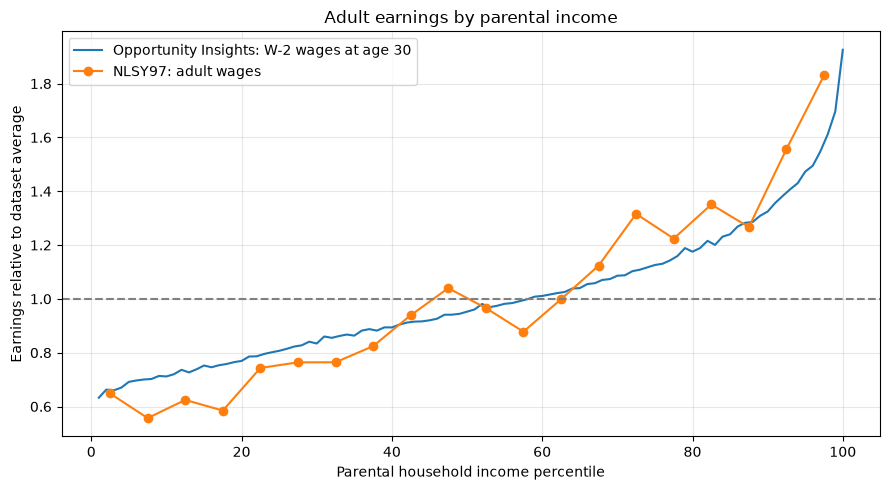

In [17]:
# Opportunity Insights: age-30 earnings by parental-income percentile
oi_curve = pd.DataFrame({
    "percentile": oi["par_pctile"],
    "earnings": (oi["w2wages_30_f"] + oi["w2wages_30_m"]) / 2,
}).sort_values("percentile").reset_index(drop=True)
oi_curve["relative"] = oi_curve["earnings"] / oi_curve["earnings"].mean()

# NLSY97: complete cases, 20 equally sized rank groups, mean wages and normalization
nlsy_comparison = (
    nlsy_clean.select(["R1204500", "U5753500"])
    .drop_nulls().to_pandas()
    .rename(columns={"R1204500": "income", "U5753500": "wages"})
)
nlsy_comparison["group"] = pd.qcut(nlsy_comparison["income"].rank(method="first"), 20, labels=False)
nlsy_curve = nlsy_comparison.groupby("group", as_index=False)["wages"].mean()
nlsy_curve["percentile"] = nlsy_curve["group"] * 5 + 2.5
nlsy_curve["relative"] = nlsy_curve["wages"] / nlsy_curve["wages"].mean()
print("NLSY97 complete-case respondents:", len(nlsy_comparison))
print("OI percentile rows:", len(oi_curve), "| NLSY97 groups:", len(nlsy_curve))
display(nlsy_curve.head())

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(oi_curve["percentile"], oi_curve["relative"], label="Opportunity Insights: W-2 wages at age 30")
ax.plot(nlsy_curve["percentile"], nlsy_curve["relative"], marker="o", label="NLSY97: adult wages")
ax.axhline(1, linestyle="--", color="gray")
ax.set(xlabel="Parental household income percentile", ylabel="Earnings relative to dataset average",
       title="Adult earnings by parental income")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Associate's degree or higher — percentage totals:


,Total percent
Low SES,100.0
Middle SES,100.0
High SES,99.9


Bachelor's degree or higher — percentage totals:


,Total percent
Low SES,100.0
Middle SES,100.0
High SES,100.0


,Parent SES,Associate's or Higher,Bachelor's or Higher
0,Low SES,9.1,8.4
1,Middle SES,5.5,4.7
2,High SES,5.2,4.9


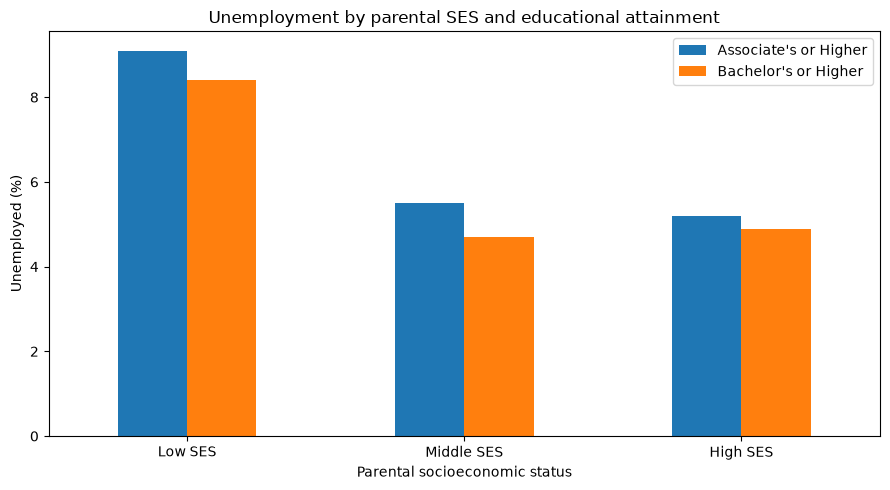

In [18]:
# ELS: group-level employment summaries, comparison and totals
ses_columns = ["Low SES", "Middle SES", "High SES"]
print("Associate's degree or higher — percentage totals:")
display(els_a[ses_columns].sum().to_frame("Total percent"))
print("Bachelor's degree or higher — percentage totals:")
display(els_b[ses_columns].sum().to_frame("Total percent"))

els_unemployment = pd.DataFrame({
    "Parent SES": ses_columns,
    "Associate's or Higher": [els_a.loc[els_a["Employment Status"] == "Unemployed", s].iloc[0] for s in ses_columns],
    "Bachelor's or Higher": [els_b.loc[els_b["Employment Status"] == "Unemployed", s].iloc[0] for s in ses_columns],
})
display(els_unemployment)
ax = els_unemployment.plot(x="Parent SES", kind="bar", figsize=(9, 5))
ax.set(xlabel="Parental socioeconomic status", ylabel="Unemployed (%)",
       title="Unemployment by parental SES and educational attainment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Reproduction checklist and scope

After **Run All**, check that:

- PSID starts with 2,362 analysis records; the left join preserves 2,362 rows, with 2,097 matching and 265 unmatched left-side records.
- NLSY97 starts with 8,984 records; the documented special zero-wage recode is applied **before** complete-case filtering; the comparison has 4,725 respondents.
- Opportunity Insights has 100 percentile rows, and the earnings comparison produces 100 OI rows and 20 NLSY97 groups.
- Each ELS cleaned table has 4 employment-status rows; source notes are excluded.

**Notebook scope:** This notebook is the standalone reproducible source for Person 4's processing and validation in Sections 4–5. The original `eda.ipynb` may still be cited for analyses or figures not reproduced here. Original publisher links and official variable definitions are not generated by code and must be sourced independently. Raw files must be obtained separately; no downloads or external API calls occur.